In [1]:
from sentence_transformers import SentenceTransformer

embed = SentenceTransformer("intfloat/multilingual-e5-large-instruct")

In [2]:
import pandas as pd
import numpy as np

augmented = pd.read_parquet("../corpus/augment/train_augment.parquet")
test      = pd.read_parquet("../corpus/augment/test_augment.parquet")

In [3]:
questions = augmented["question"]
new_embed = embed.encode_document(list(questions))
augmented["embedding"] = list(new_embed)

In [4]:
questions = test["question"]
new_embed = embed.encode_document(list(questions))
test["embedding"] = list(new_embed)

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(np.stack(augmented["embedding"]))
forest = RandomForestClassifier()
fitted = forest.fit(
    scaler.transform(np.stack(augmented["embedding"])),
    np.asarray(augmented["action"]),
)

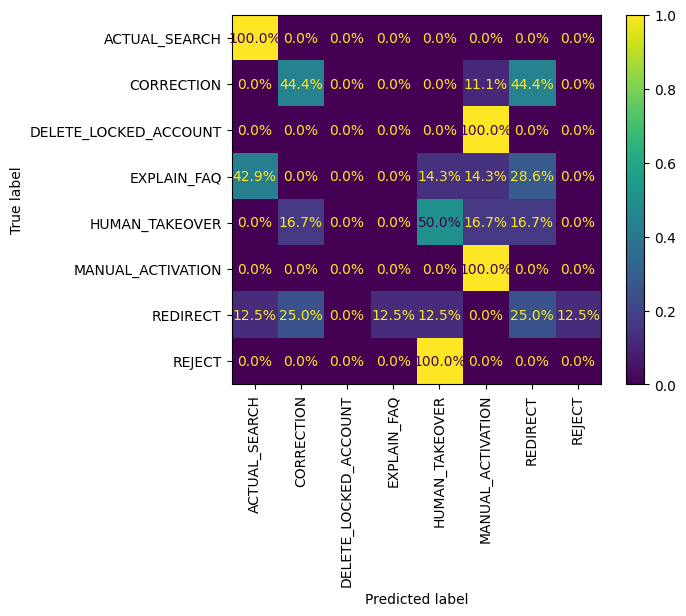

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

X_ = scaler.transform(np.stack(test["embedding"]))
Y_ = np.asarray(test["action"])
#
y  = fitted.predict(X_)
ConfusionMatrixDisplay.from_predictions(
    Y_, y,
    values_format=".1%",
    xticks_rotation="vertical",
    normalize="true",
)

In [8]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
    estimator = LinearSVC(),
    param_distributions = {
        "loss": ["hinge", "squared_hinge"],
        "C": list(range(200)),
        "max_iter": list(range(1000, 20000)),
    },
    n_jobs=-1,
    n_iter= 28*5,
    cv=3,
)

search.fit(
    np.stack(augmented["embedding"]),
    np.asarray(augmented["action"]),
)

softmax = search.best_estimator_

/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.w

In [11]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler

scaler  = StandardScaler()
scaler  = scaler.fit(np.stack(augmented["embedding"]))

softmax = LinearSVC(max_iter=5000)
softmax = softmax.fit(
    scaler.transform(np.stack(augmented["embedding"])),
    np.asarray(augmented["action"]),
)

/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


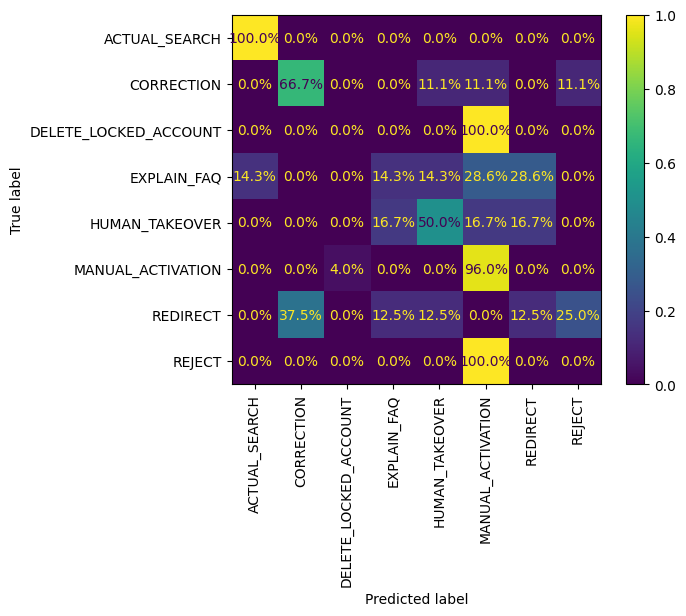

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

X_ = scaler.transform(np.stack(test["embedding"]))
Y_ = np.asarray(test["action"])
#
y  = softmax.predict(X_)
ConfusionMatrixDisplay.from_predictions(
    Y_, y,
    values_format=".1%",
    xticks_rotation="vertical",
    normalize="true",
)